Dataset Shape: (284807, 31)
Class Distribution:
Class
0    284315
1       492
Name: count, dtype: int64


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 16)                  │             496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 16)                  │             144 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 30)                  │             510 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,286 (5.02 KB)

 Trainable params: 1,286 (5.02 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - loss: 0.7762 - mae: 0.6020 - val_loss: 0.6202 - val_mae: 0.5534
Epoch 2/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.6008 - mae: 0.5355 - val_loss: 0.5553 - val_mae: 0.5258
Epoch 3/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.5557 - mae: 0.5174 - val_loss: 0.5280 - val_mae: 0.5129
Epoch 4/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.5333 - mae: 0.5071 - val_loss: 0.5098 - val_mae: 0.5027
Epoch 5/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.5173 - mae: 0.4986 - val_loss: 0.4979 - val_mae: 0.4958
Epoch 6/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.5050 - mae: 0.4919 - val_loss: 0.4854 - val_mae: 0.4874
Epoch 7/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.4944 - mae: 0.4841 - val_loss: 0.4792 - val_mae: 0.4839
Epoch 8/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.4856 - mae: 0.4778 - val_loss: 0.4699 - val_mae: 0.4754
Epoch 9/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - lo

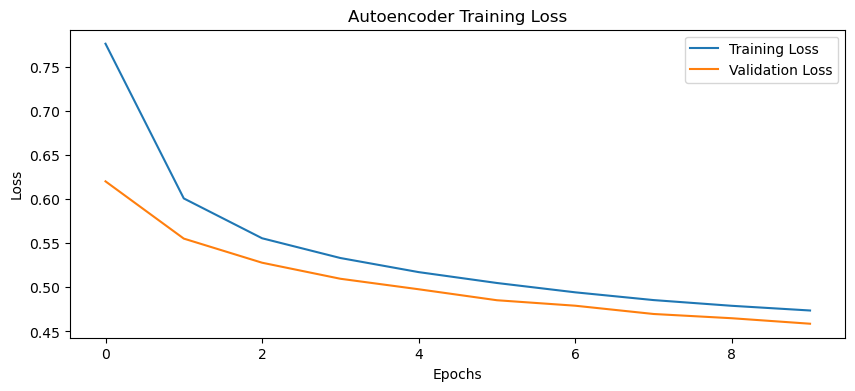

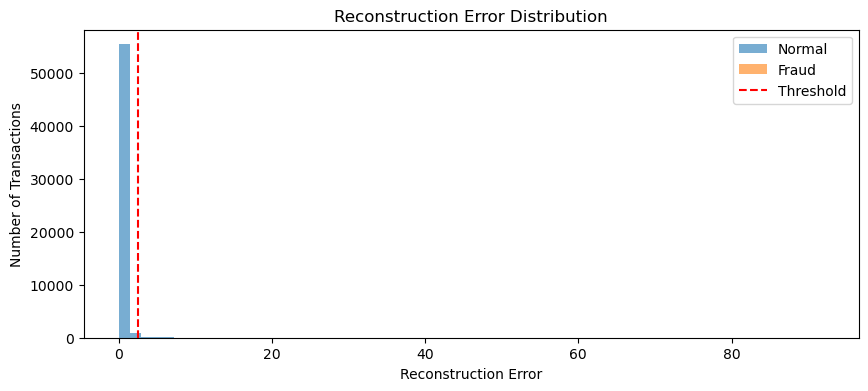

In [1]:
# Assignment 3A: Credit Card Fraud Detection Using Autoencoder

# Step 1: Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,confusion_matrix)
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam


# Step 2: Load Dataset
data = pd.read_csv("creditcard.csv")

print("Dataset Shape:", data.shape)
print("Class Distribution:")
print(data["Class"].value_counts())


# Step 3: Separate Features and Labels
X = data.drop("Class", axis=1)
y = data["Class"]


# Step 4: Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# Step 5: Use Only Normal Transactions for Training
X_train_normal = X_train[y_train == 0]


# Step 6: Scale Features
scaler = StandardScaler()

X_train_normal = scaler.fit_transform(X_train_normal)
X_test = scaler.transform(X_test)


# Step 7: Define Autoencoder Architecture
model = Sequential([
    Input(shape=(30,)),

    Dense(16, activation="relu"),
    Dense(8, activation="relu"),

    Dense(16, activation="relu"),
    Dense(30, activation="linear")
])


# Step 8: Compile Model
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

model.summary()


# Step 9: Train Autoencoder
history = model.fit(
    X_train_normal,
    X_train_normal,
    epochs=10,
    batch_size=256,
    validation_split=0.1,
    shuffle=True
)


# Step 10: Calculate Training Reconstruction Error
train_predictions = model.predict(
    X_train_normal,
    verbose=0
)

train_error = np.mean(
    np.square(X_train_normal - train_predictions),
    axis=1
)


# Step 11: Set Threshold
threshold = np.percentile(train_error, 99)

print("Threshold:", threshold)


# Step 12: Calculate Testing Reconstruction Error
test_predictions = model.predict(X_test, verbose=0)

test_error = np.mean(
    np.square(X_test - test_predictions),
    axis=1
)


# Step 13: Detect Fraud
y_pred = (test_error > threshold).astype(int)


# Step 14: Evaluate Model
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))


# Step 15: Plot Training Loss
plt.figure(figsize=(10, 4))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Autoencoder Training Loss")
plt.legend()
plt.show()


# Step 16: Plot Reconstruction Errors
plt.figure(figsize=(10, 4))

plt.hist(
    test_error[y_test.to_numpy() == 0],
    bins=50,
    alpha=0.6,
    label="Normal"
)

plt.hist(
    test_error[y_test.to_numpy() == 1],
    bins=50,
    alpha=0.6,
    label="Fraud"
)

plt.axvline(
    threshold,
    color="red",
    linestyle="--",
    label="Threshold"
)

plt.xlabel("Reconstruction Error")
plt.ylabel("Number of Transactions")
plt.title("Reconstruction Error Distribution")
plt.legend()
plt.show()